# 07 · CardioTwin risk engine

One Python entry point, `evaluate_patient_risk(patient_profile, clinical_readings, wearable_readings, baseline=None, now=None)`,
that the phone app (patient and doctor mode) and the Wear OS watch call. It returns the score, the LOW / MODERATE / HIGH tier,
a separate emergency state, the reasons (SHAP), the personal baseline and trends, per-signal freshness, a SAR narrative and an
audit reference. When readings are stale, missing or invalid it returns `INSUFFICIENT_DATA`; when the model fails it returns
`MODEL_ERROR`. It never turns either into a LOW result or a made-up score.

The engine lives in the `risk_engine/` folder next to this notebook. This notebook builds its start-up artifacts, checks it
against notebook 05, demonstrates every feature on the real test patients, runs the automated tests and saves all outputs.

**Data.** The watch readings here are MIMIC-IV demo ICU vitals replayed as if they came from the watch. They are labelled as
replay data everywhere. The only synthetic data is in the automated tests, where it is labelled as a test fixture. Nothing is trained
on synthetic data.

**Safety.** Research prototype, not a medical device. Thresholds are provisional, emergency rules are a draft built from NEWS2
bands, and nothing here has had clinical review.

## 0 · Setup

In [1]:
import json, sys, time, warnings, subprocess, platform, copy
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
warnings.filterwarnings("ignore", category=DeprecationWarning)

ROOT = Path("..") if Path("../data").exists() else Path(".")  # repo root (notebooks run from notebooks/)
sys.path[:0] = [str(ROOT.resolve()), str((ROOT / "src").resolve())]
RES = ROOT / "results" / "risk_engine"; CH = ROOT / "charts" / "risk_engine"; REP = ROOT / "reports" / "risk_reports"
PAY = RES / "payloads"
for d in (RES, CH, REP, PAY, RES / "audit"):
    d.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREEN, RED, GREY, PURPLE = "#2a6fb0", "#e08a1e", "#3a9a5b", "#c0392b", "#8a8a8a", "#7b5ea7"
TIER_COLOR = {"LOW": GREEN, "MODERATE": ORANGE, "HIGH": RED}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

def savefig(name):
    plt.tight_layout(); plt.savefig(CH / f"{name}.png", dpi=130, bbox_inches="tight"); plt.close()
    display(Image(str(CH / f"{name}.png")))

def dump(obj, path):
    Path(path).write_text(json.dumps(obj, indent=1, default=str), encoding="utf-8")

import risk_engine
from risk_engine import RiskEngine, load_config, evaluate_patient_risk, build_artifacts, views, whatif, report, drift_service
from risk_engine.replay import ReplayData, REPLAY_SOURCE
from risk_engine.alert_service import AlertService
from risk_engine.audit_service import AuditService
print("python", platform.python_version(), "| pandas", pd.__version__, "| engine", risk_engine.ENGINE_VERSION)

python 3.13.16 | pandas 2.2.3 | engine risk-engine-1.0.0


## 1 · Repository assessment

What the engine is built on, read from the files saved by notebooks 05 and 06 (nothing is retrained here).

In [2]:
cfg = load_config()
meta = json.loads((ROOT / "models" / "model_metadata.json").read_text())
ops = json.loads((ROOT / "models" / "operating_points.json").read_text())
calsel = pd.read_csv(ROOT / "results" / "calibration_selection.csv")
w = meta["watch"]
assess = {
    "deployed model (phone + watch)": f"{w['name']} {w['version']}: {w['model_type']}, {w['n_features']} inputs, file {w['file']}",
    "reference model (hospital data)": f"{meta['full']['name']}: {meta['full']['model_type']} (needs labs / ICU data, so not used by the watch engine)",
    "prediction target": w["label_definition"],
    "horizon": f"{w['horizon_h']} hours",
    "training data": f"{w['train_patients']} patients, {w['train_hours']} hours, {w['train_event_hours']} event hours (MIMIC-IV demo ICU stays)",
    "preprocessing": "fitted SimpleImputer(median, with missing flags) -> StandardScaler -> LogisticRegression, saved inside the model file",
    "calibration": f"'{w['calibration']}': notebook 05 compared none / sigmoid / isotonic and kept 'none' (lowest CV Brier for the watch model)",
    "risk thresholds": f"MODERATE >= {ops['watch']['operating_points']['moderate']}, HIGH >= {ops['watch']['operating_points']['high']} ({ops['watch']['rule']})",
    "threshold status": "provisional (chosen on cross-validation, not clinically approved)",
    "feature code": "twin_preprocess.py (training feature functions, reused by the engine)",
    "existing rules": "twin_rules.py symptom_check (reused by the emergency layer)",
    "SHAP": "notebook 06 exact linear SHAP (reused, adapted to one row at a time)",
    "app framework": "no web dashboard: phone app (patient / doctor mode) + Wear OS watch, so the engine returns the payloads each screen renders",
}
for k, v in assess.items():
    print(f"{k:32s} {v}")
print()
print(calsel[calsel.feature_set == "watch"][["method", "Brier", "log_loss", "mean_predicted", "observed_rate"]].to_string(index=False))
dump(assess, RES / "repository_assessment.json")

deployed model (phone + watch)   cardiotwin-watch-24h 1.0.0+2026-10-18: Logistic regression (baseline), 46 inputs, file models/cardiotwin_watch_24h.pkl
reference model (hospital data)  cardiotwin-full-24h: LightGBM (Optuna) (needs labs / ICU data, so not used by the watch engine)
prediction target                first vasopressor start, lactate >= 4 or in-hospital death in (t, t+24h], t = end of the hour bin
horizon                          24 hours
training data                    59 patients, 3391 hours, 145 event hours (MIMIC-IV demo ICU stays)
preprocessing                    fitted SimpleImputer(median, with missing flags) -> StandardScaler -> LogisticRegression, saved inside the model file
calibration                      'none': notebook 05 compared none / sigmoid / isotonic and kept 'none' (lowest CV Brier for the watch model)
risk thresholds                  MODERATE >= 0.0362, HIGH >= 0.0759 (HIGH = lowest cut-off with <= 1 alert per patient-day (CV); MODERATE = highest cut-o

## 2 · Engine start-up artifacts

Built from the **training split only**: input ranges and medians (out-of-distribution and drift checks, wording), the SHAP
background, 50 bootstrap refits of the watch model (shown as model variance, not as a validated interval) and a manifest
with the model file's SHA-256, which the engine checks at every start.

In [3]:
t0 = time.time()
manifest = build_artifacts.build(ROOT, cfg, n_boot=50, seed=42)
print(json.dumps(manifest, indent=1))
print(f"built in {time.time() - t0:.1f} s")

{
 "created_at": "2026-10-18T14:13:16+00:00",
 "model_file": "models/cardiotwin_watch_24h.pkl",
 "model_sha256": "c66823982669d7cc6fd5e1d7f0277566144efc51cb553cfeb75b591c7ad43752",
 "model_version": "1.0.0+2026-10-18",
 "config_sha256": "58e1788635f14ac8f68a68f01c79a37ac2d37b9489955d6272e953a6095313e6",
 "artifacts": {
  "bootstrap_ensemble.joblib": "44aa3cca8099e3b32c4ecd492894a5b56f498d472b579ee8f3883b90a1a1ef6b",
  "shap_background.json": "2e534098cce6102634e39dee1302c2825f175e236ee6c70ff8b318c45e417652",
  "training_reference.json": "e3088a75fb25acd54e452c093097b75f23eb96bf49c26636622436417811dd3e"
 }
}
built in 3.5 s


## 3 · Load the engine once, and check it against notebook 05

In [4]:
t0 = time.time()
ENGINE = RiskEngine(ROOT, cfg)
print(f"engine loaded in {time.time() - t0:.2f} s; model error: {ENGINE.model_error}")
print("model:", json.dumps(ENGINE.model.info(), indent=1))
R = ReplayData(ROOT)
STAYS = R.test_stays()
print(f"{len(STAYS)} test stays, {len(R.test)} test hours; replay source label: '{REPLAY_SOURCE}'")

engine loaded in 0.02 s; model error: None
model: {
 "name": "cardiotwin-watch-24h",
 "version": "1.0.0+2026-10-18",
 "sha256": "c66823982669d7cc6fd5e1d7f0277566144efc51cb553cfeb75b591c7ad43752",
 "target": "first vasopressor start, lactate >= 4 mmol/L or in-hospital death",
 "horizon": "24 hours",
 "population": "adult ICU stays, MIMIC-IV demo (100 patients); not validated outside the ICU",
 "calibration_status": "uncalibrated",
 "calibration_method": "none",
 "calibration_note": "No calibrator applied: notebook 05 compared none, sigmoid and isotonic and kept 'none' because calibrating did not lower the cross-validated Brier score. The output is the logistic regression's own probability, not a separately calibrated one.",
 "calibration_version": "1.0.0+2026-10-18:none"
}
19 test stays, 1077 test hours; replay source label: 'replay: MIMIC-IV demo ICU charted vitals (not real watch data)'


In [5]:
# Parity: features built by the engine from raw replayed readings vs the training feature table, and the engine's score
# vs the score notebook 05 saved, for every test hour.
from risk_engine import input_validator, feature_builder
rows = []
for sid in STAYS:
    hours = R.test[R.test.stay_id == sid].hour.sort_values()
    req = R.request(sid, hours.max())
    now = pd.Timestamp(req["now"])
    v = input_validator.validate(req["patient_profile"], req["clinical_readings"], req["wearable_readings"], now, cfg)
    tab = feature_builder.hourly_table(v.readings, now, v.profile.get("hist_af"))
    st = feature_builder.static_values(v)
    Xe = feature_builder.feature_matrix(tab, st, ENGINE.model.features).assign(hour=tab.hour.values).set_index("hour")
    ref = R.mf[R.mf.stay_id == sid].set_index("hour")
    gap = bool((R.dyn[R.dyn.stay_id == sid].hour.diff() > pd.Timedelta(hours=1)).any())
    for h in hours:
        if h not in Xe.index:
            continue
        # profile values such as the medicine count change during a stay: use the profile as it was at that hour
        vh = input_validator.validate(R.profile(sid, h), R.clinical(sid, h), [], h + pd.Timedelta(hours=1), cfg)
        for k, val in feature_builder.static_values(vh).items():
            if k in ENGINE.model.features:
                Xe.loc[h, k] = val
        a, b = Xe.loc[h, ENGINE.model.features].astype(float), ref.loc[h, ENGINE.model.features].astype(float)
        diff = (a - b).abs()
        mism = [f for f in ENGINE.model.features if not ((pd.isna(a[f]) and pd.isna(b[f])) or diff[f] < 1e-6)]
        p = ENGINE.model.raw(Xe.loc[[h], ENGINE.model.features])[0]
        rows.append({"stay_id": sid, "hour": h, "stay_has_hour_gaps": gap, "n_feature_mismatch": len(mism),
                     "mismatched": ",".join(mism), "engine_score": p,
                     "nb05_score": float(R.test[(R.test.stay_id == sid) & (R.test.hour == h)].risk_watch.iloc[0])})
PAR = pd.DataFrame(rows)
PAR["abs_diff"] = (PAR.engine_score - PAR.nb05_score).abs()
PAR["same_tier"] = [ENGINE.policy.tier(a) == ENGINE.policy.tier(b) for a, b in zip(PAR.engine_score, PAR.nb05_score)]
PAR.to_csv(RES / "parity_vs_notebook05.csv", index=False)
print(f"{len(PAR)} test hours compared")
print(PAR.groupby("stay_has_hour_gaps").agg(hours=("abs_diff", "size"), exact_features=("n_feature_mismatch", lambda x: f"{100 * (x == 0).mean():.1f}%"),
      median_abs_diff=("abs_diff", "median"), max_abs_diff=("abs_diff", "max"), same_tier=("same_tier", "mean")).round(5))
print("\ninputs that differ most often:", pd.Series(",".join(PAR.mismatched).split(",")).replace("", np.nan).dropna().value_counts().head(6).to_dict())

1077 test hours compared
                    hours exact_features  median_abs_diff  max_abs_diff  \
stay_has_hour_gaps                                                        
False                 281          81.5%              0.0       0.00129   
True                  796          54.3%              0.0       0.04162   

                    same_tier  
stay_has_hour_gaps             
False                 1.00000  
True                  0.99623  

inputs that differ most often: {'hr_vs_baseline': 221, 'bmi': 211, 'hr_sd_24h': 151, 'rr_night_minus_day_24h': 141, 'rr_vs_baseline': 123, 'hr_trend_24h': 122}


Where a stay's hourly table has missing hours, training rolled its windows over **rows** while the engine rolls over **clock
hours** (a live watch has real gaps, so the engine fills the hour grid and forward-fills at most 4 hours, as in training). The
rest of the difference comes from `rr_vs_baseline` / `hr_vs_baseline` and from BMI: when BMI was unknown, training used a
pre-filled value, and the engine leaves it missing for the fitted imputer. The table above shows how often this changes the
score and the tier.

## 4 · One full evaluation (the highest-risk test patient at the end of their stay)

In [6]:
def run(sid, hour=None, engine=None, **kw):
    hour = R.last_hour(sid) if hour is None else hour
    req = R.request(sid, hour)
    req.update(kw)
    return (engine or ENGINE).evaluate(**req), req

EX_SID = 31316840
res, req = run(EX_SID)
d = res.model_dump(mode="json")
dump(d, RES / f"example_result_{EX_SID}.json")
print(f"status {d['status']} | raw {d['risk']['raw_output']} | tier {d['risk']['tier']} | emergency {d['emergency']['state']} ({d['emergency']['rule_id']})")
print("one line:", d["sar"]["one_line"])
print("\nmodel:", {k: d["model"][k] for k in ("version", "target", "horizon", "calibration_status")})
print("risk:", {k: d["risk"][k] for k in ("raw_output", "calibrated_probability", "score_scale", "tier", "thresholds", "tier_reason", "provisional_policy")})
print("uncertainty:", d["risk"]["uncertainty"])
print("\nfreshness:")
print(pd.DataFrame(d["data_quality"]["freshness_by_signal"]).T[["status", "last_valid_reading", "age_minutes", "max_age_minutes", "coverage_pct_24h", "source"]])
print("\ntop 3 reasons:")
for c in d["explanation"]["top_contributors"]:
    print(f"  {c['rank']}. {c['reason']}: {c['direction']} (SHAP {c['shap_log_odds']:+.3f}, odds x{c['odds_multiplier']}) <- " +
          "; ".join(f"{i['feature']}={i['value']} {i['unit'] or ''}" for i in c["inputs"]))
print("\npolicy breakdown:", json.dumps(d["policy_breakdown"], indent=1))
print("\nnext actions:"); [print("  -", a) for a in d["next_actions"]]

status OK | raw 0.080576 | tier HIGH | emergency REVIEW_REQUIRED (EMG-VIT-00)
one line: HIGH: 8.1% for first vasopressor start, lactate >= 4 mmol/L or in-hospital death within 24 hours; data warnings: 2.

model: {'version': '1.0.0+2026-10-18', 'target': 'first vasopressor start, lactate >= 4 mmol/L or in-hospital death', 'horizon': '24 hours', 'calibration_status': 'uncalibrated'}
risk: {'raw_output': 0.080576, 'calibrated_probability': None, 'score_scale': 'model probability (0-1), uncalibrated', 'tier': 'HIGH', 'thresholds': {'moderate': 0.0362, 'high': 0.0759}, 'tier_reason': 'Score 0.0806 is at or above the HIGH cut-off 0.0759.', 'provisional_policy': True}
uncertainty: {'p05': 0.0222, 'p50': 0.0833, 'p95': 0.2002, 'n_refits': 50, 'method': 'patient-level bootstrap refits of the watch model (notebook 07 artifact)', 'validated': False, 'note': 'Shows how much the score moves when the model is retrained on other samples of the 59 training patients. Not a validated confidence interval

[None, None, None, None]

In [7]:
display(Markdown("### SAR (every sentence carries its evidence)"))
for part in ("situation", "assessment", "recommendation"):
    display(Markdown(f"**{part.title()}**"))
    for s in res.sar.sentences[part]:
        ev = "; ".join(", ".join(f"{k}={v}" for k, v in e.items() if k in ("type", "signal", "feature", "timestamp", "time_window", "rule_id", "model_version", "policy_version") and v) for e in s.evidence)
        display(Markdown(f"- {s.text}  \n  <sub>evidence: {ev}</sub>"))
display(Markdown("**Limitations:** " + " ".join(res.sar.limitations)))

### SAR (every sentence carries its evidence)

**Situation**

- Model output 8.1% (model probability (uncalibrated)) for first vasopressor start, lactate >= 4 mmol/L or in-hospital death within 24 hours; tier HIGH (provisional cut-offs: MODERATE >= 0.0362, HIGH >= 0.0759).  
  <sub>evidence: type=model, model_version=1.0.0+2026-10-18; type=policy, policy_version=RE-POLICY-1.0-provisional; type=model_output</sub>

- Evaluated at 2135-01-13 10:00:00.  
  <sub>evidence: type=calculation</sub>

- Latest valid watch readings: Heart rate at 2135-01-13 09:00:00 (60 min old, fresh); SpO2 at 2135-01-13 09:00:00 (60 min old, fresh); Breathing rate at 2135-01-13 09:00:00 (60 min old, fresh).  
  <sub>evidence: type=reading, signal=hr, timestamp=2135-01-13 09:00:00; type=reading, signal=spo2, timestamp=2135-01-13 09:00:00; type=reading, signal=rr, timestamp=2135-01-13 09:00:00</sub>

...

- Prompt clinical review is appropriate, with a full set of observations (BP, temperature, consciousness, SpO2, breathing rate, heart rate).  
  <sub>evidence: type=policy; type=policy, policy_version=RE-POLICY-1.0-provisional</sub>

- Score NEWS2 at the review: 5-6, or any single parameter scoring 3, calls for an urgent response; 7 or more calls for an emergency response, per local escalation policy.  
  <sub>evidence: type=policy; type=policy, policy_version=RE-POLICY-1.0-provisional</sub>

- Clinician review is appropriate.  
  <sub>evidence: type=policy</sub>

- This output supports, and never replaces, clinical judgement. It suggests no treatment.  
  <sub>evidence: type=policy</sub>

**Limitations:** 5 inputs were filled in by the model. The bootstrap range crosses a tier cut-off, so the tier is uncertain. SHAP shows how the model weighed the inputs; it is not proof of cause. Trained on ICU data from 100 patients (adult ICU stays, MIMIC-IV demo (100 patients); not validated outside the ICU); thresholds are provisional. The model output is not separately calibrated (see model.calibration_note).

## 5 · Data sufficiency gate and graceful failure

Each case below uses a real test patient's request with one thing changed. Every one must end in a clear status, never in a
LOW score.

In [8]:
base_req = R.request(EX_SID, R.last_hour(EX_SID))
now0 = pd.Timestamp(base_req["now"])
def variant(name, **chg):
    r = copy.deepcopy(base_req); r.update(chg); return name, r

cases = [
    variant("valid, fresh readings"),
    variant("watch off for 5 h (stale)", now=now0 + pd.Timedelta(hours=5)),
    variant("no SpO2 readings (missing)", wearable_readings=[x for x in base_req["wearable_readings"] if x["signal"] != "spo2"]),
    variant("SpO2 sent in a wrong unit (invalid)", wearable_readings=[dict(x, unit="mmHg") if x["signal"] == "spo2" else x for x in base_req["wearable_readings"]]),
    variant("age missing from profile", patient_profile={**base_req["patient_profile"], "age_at_admit": None}),
    variant("no readings at all", wearable_readings=[]),
]
out = []
for name, r in cases:
    x = ENGINE.evaluate(**r, simulation=True, record=False)
    out.append({"case": name, "status": x.status.value, "reason_code": x.status_reason_code, "tier": x.risk.tier.value if x.risk.tier else None,
                "score": x.risk.raw_output, "emergency": x.emergency.state.value, "patient_screen": views.phone_patient(x)["screen"],
                "watch_face": views.watch(x).get("title")})

# model and SHAP failures, injected
class BrokenExplainer:
    def __call__(self, *a, **k): raise RuntimeError("SHAP service unavailable")
e2 = RiskEngine(ROOT, cfg, explainer=BrokenExplainer(), alert_service=AlertService(cfg), audit_service=AuditService(cfg))
x = e2.evaluate(**base_req, simulation=True, record=False)
out.append({"case": "SHAP service down", "status": x.status.value, "reason_code": x.status_reason_code, "tier": x.risk.tier.value,
            "score": x.risk.raw_output, "emergency": x.emergency.state.value, "patient_screen": views.phone_patient(x)["screen"],
            "watch_face": views.watch(x).get("title"), "explanation": x.explanation.status.value})
import tempfile
bad_manifest = Path(tempfile.mkdtemp()) / "manifest.json"
bad_manifest.write_text(json.dumps({"model_sha256": "0" * 64}))      # simulates a changed or corrupted model file
e3 = RiskEngine(ROOT, load_config(overrides={"model.integrity_manifest": str(bad_manifest)}),
                alert_service=AlertService(cfg), audit_service=AuditService(cfg))
x = e3.evaluate(**base_req, simulation=True, record=False)
out.append({"case": "model file failed integrity check", "status": x.status.value, "reason_code": x.status_reason_code, "tier": None,
            "score": x.risk.raw_output, "emergency": x.emergency.state.value, "patient_screen": views.phone_patient(x)["screen"],
            "watch_face": views.watch(x).get("title")})
GATE = pd.DataFrame(out)
GATE.to_csv(RES / "sufficiency_and_failure_cases.csv", index=False)
GATE

,case,status,reason_code,tier,score,emergency,patient_screen,watch_face,explanation
0,"valid, fresh readings",OK,None,HIGH,0.080576,REVIEW_REQUIRED,HIGH,Re-measure,NaN
1,watch off for 5 h (stale),INSUFFICIENT_DATA,STALE_DATA,None,NaN,NOT_ASSESSABLE,CANNOT_UPDATE,No update,NaN
2,no SpO2 readings (missing),INSUFFICIENT_DATA,MISSING_MANDATORY,None,NaN,NOT_TRIGGERED,CANNOT_UPDATE,No update,NaN
3,SpO2 sent in a wrong unit (invalid),INSUFFICIENT_DATA,INVALID_DATA,None,NaN,NOT_TRIGGERED,CANNOT_UPDATE,No update,NaN
4,age missing from profile,INSUFFICIENT_DATA,MISSING_MANDATORY,None,NaN,REVIEW_REQUIRED,CANNOT_UPDATE,Re-measure,NaN
5,no readings at all,INSUFFICIENT_DATA,NO_VALID_READINGS,None,NaN,NOT_ASSESSABLE,CANNOT_UPDATE,No update,NaN
6,SHAP service down,OK,None,HIGH,0.080576,REVIEW_REQUIRED,HIGH,Re-measure,UNAVAILABLE
7,model file failed integrity check,MODEL_ERROR,INTEGRITY_FAILED,None,NaN,REVIEW_REQUIRED,UNAVAILABLE,Re-measure,NaN


## 6 · Emergency escalation layer

Evaluated on validated readings and reported symptoms **before and independently of** the model. Draft rules, built from the
NEWS2 single-parameter red bands (score 3) and the project's symptom rule:

| Rule | State | Meaning |
|---|---|---|
| EMG-SYM-01 | TRIGGERED | chest pain with spreading pain, cold sweat or breathlessness (or symptom score ≥ 6) |
| EMG-VIT-02 | TRIGGERED | two or more watch signals confirmed (≥ 2 readings within 60 min) in a red band |
| EMG-VIT-01 | REVIEW_REQUIRED | one signal confirmed in a red band (NEWS2: urgent clinical review) |
| EMG-SYM-02 | REVIEW_REQUIRED | symptom score ≥ 3 |
| EMG-VIT-00 | REVIEW_REQUIRED | one unconfirmed red-band reading: re-measure |

**Replay note.** The replayed ICU vitals arrive once an hour, so two red-band readings can never fall inside the 60-minute
confirmation window while both are under 90 minutes old. On this data the vitals rules can therefore only raise
"re-measure" prompts (EMG-VIT-00); a watch sampling every few minutes can confirm a reading. The TRIGGERED path is shown
below with a symptom report marked as demonstration input, and it is covered by the automated tests.

The call option opens the phone dialler with **112** (India's national emergency number, configured for an India deployment).
The user presses Call; the app never dials by itself and never claims an ambulance was sent.

In [9]:
# How often each rule fires on the real test stays, hour by hour (replayed readings only, no model involved)
from risk_engine import emergency_rules
em_rows = []
for sid in STAYS:
    for h in R.test[R.test.stay_id == sid].hour.sort_values():
        req = R.request(sid, h); now = pd.Timestamp(req["now"])
        v = input_validator.validate(req["patient_profile"], [], req["wearable_readings"], now, cfg)
        e = emergency_rules.evaluate(v.readings, None, now, cfg)
        em_rows.append({"stay_id": sid, "hour": h, "state": e.state.value, "rule_id": e.rule_id})
EMR = pd.DataFrame(em_rows).merge(R.test[["stay_id", "hour", "y_24h"]], on=["stay_id", "hour"])
EMR.to_csv(RES / "emergency_rules_test_hours.csv", index=False)
summ = EMR.groupby("state").agg(hours=("y_24h", "size"), stays=("stay_id", "nunique"), event_within_24h=("y_24h", "mean")).round(3)
print(summ); print(); print(EMR.rule_id.value_counts(dropna=False))
summ.to_csv(RES / "emergency_rules_summary.csv")

                 hours  stays  event_within_24h
state                                          
NOT_ASSESSABLE       2      2             0.000
NOT_TRIGGERED      873     19             0.056
REVIEW_REQUIRED    202     16             0.158

rule_id
None          875
EMG-VIT-00    202
Name: count, dtype: int64


In [10]:
# A demonstration request: the same patient, plus a patient-reported symptom check (labelled DEMONSTRATION input).
demo_prof = {**base_req["patient_profile"], "reported_symptoms": {"chest_pain": True, "cold_sweat": True, "breathless": False,
             "timestamp": str(now0 - pd.Timedelta(minutes=4)), "note": "DEMONSTRATION input, not from the patient record"}}
EM_ENGINE = RiskEngine(ROOT, cfg, alert_service=AlertService(cfg), audit_service=AuditService(cfg))
em_res = EM_ENGINE.evaluate(demo_prof, base_req["clinical_readings"], base_req["wearable_readings"], now=now0)
modal = em_res.emergency.modal
print("state:", em_res.emergency.state.value, "| rule:", em_res.emergency.rule_id, "| alert:", em_res.alert["decision"])
print("reason:", em_res.emergency.reason)
dump(modal, PAY / "emergency_modal_phone.json")
dump(modal["watch"], PAY / "emergency_watch.json")
print(json.dumps({k: modal[k] for k in ("title", "icon", "headline", "instructions", "dismissible", "dispatch_status")}, indent=1))
print(json.dumps(modal["actions"][0], indent=1))
print(json.dumps(modal["accessibility"], indent=1))

state: TRIGGERED | rule: EMG-SYM-01 | alert: NEW_EMERGENCY
reason: Reported: chest pain, cold sweat (score 5) [EMG-SYM-01] | Oxygen saturation 90.0 % at 2135-01-13 09:00:00 (<= 91 (NEWS2 score 3)) [EMG-VIT-00]
{
 "title": "Emergency warning",
 "icon": "warning_triangle",
 "headline": "Your readings or symptoms meet an emergency rule.",
 "instructions": [
  "Stop what you are doing and sit or lie down.",
  "If you have chest pain, trouble breathing, or feel faint, call 112 now or ask someone nearby to call.",
  "Do not drive yourself to hospital.",
  "Keep your phone with you and unlock the door if you can."
 ],
 "dismissible": false,
 "dispatch_status": "NOT_DISPATCHED"
}
{
 "id": "call_emergency",
 "type": "open_dialer",
 "number": "112",
 "uri": "tel:112",
 "country": "IN",
 "label": "Call 112",
 "requires_user_confirmation": true,
 "auto_dial": false,
 "confirm_text": "This opens your phone's dialler with 112 filled in. You press Call yourself. CardioTwin does not contact emergency 

/tmp/ipykernel_586/4123428134.py:22: UserWarning: Glyph 128222 (\N{TELEPHONE RECEIVER}) missing from font(s) Inter, DejaVu Sans, DejaVu Sans.
  plt.tight_layout(); plt.savefig(CH / f"{name}.png", dpi=130, bbox_inches="tight"); plt.close()


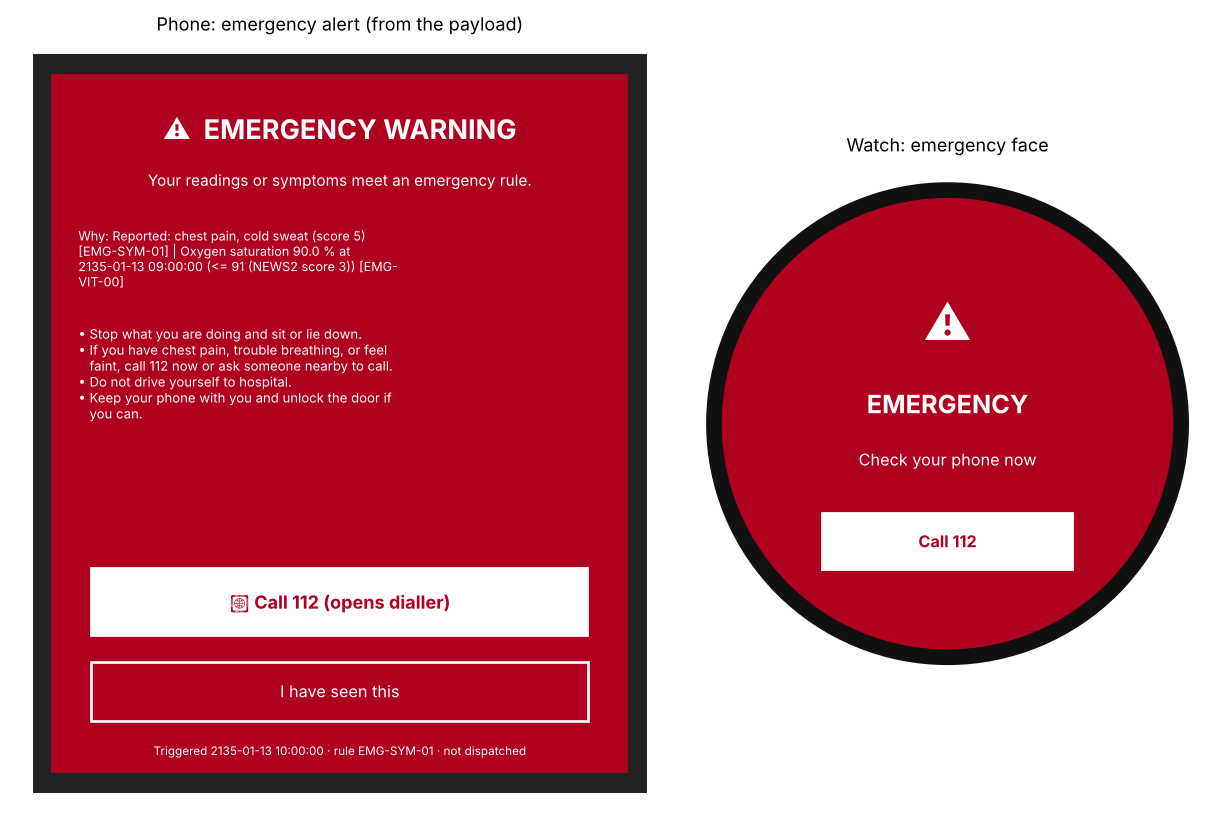

In [11]:
# What the phone and the watch show (drawn from the payload only)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 6.4), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]; ax.set_xlim(0, 10); ax.set_ylim(0, 18); ax.axis("off")
ax.add_patch(plt.Rectangle((0.3, 0.3), 9.4, 17.4, color="#222", zorder=0, lw=0))
ax.add_patch(plt.Rectangle((0.6, 0.8), 8.8, 16.4, color=modal["colors"]["background"], zorder=1))
ax.text(5, 15.7, f"{modal['icon_glyph']}  {modal['title'].upper()}", color="white", ha="center", fontsize=15, weight="bold", zorder=2)
ax.text(5, 14.6, modal["headline"], color="white", ha="center", fontsize=8.5, zorder=2, wrap=True)
import textwrap
ax.text(1.0, 13.6, "\n".join(textwrap.wrap("Why: " + modal["reason"], 52)), color="white", fontsize=7, va="top", zorder=2)
ax.text(1.0, 11.3, "\n".join("• " + "\n   ".join(textwrap.wrap(s, 50)) for s in modal["instructions"]), color="white", fontsize=7.3, va="top", zorder=2)
ax.add_patch(plt.Rectangle((1.2, 4.0), 7.6, 1.6, color="white", zorder=2))
ax.text(5, 4.8, "📞 " + modal["actions"][0]["label"] + " (opens dialler)", color=modal["colors"]["background"], ha="center", va="center", fontsize=10, weight="bold", zorder=3)
ax.add_patch(plt.Rectangle((1.2, 2.0), 7.6, 1.4, fill=False, ec="white", lw=1.5, zorder=2))
ax.text(5, 2.7, modal["actions"][1]["label"], color="white", ha="center", va="center", fontsize=9, zorder=3)
ax.text(5, 1.2, f"Triggered {modal['triggered_at']} · rule {modal['rule_id']} · not dispatched", color="white", ha="center", fontsize=6.5, zorder=3)
ax.set_title("Phone: emergency alert (from the payload)", fontsize=10)
ax = axes[1]; ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off"); ax.set_aspect("equal")
ax.add_patch(plt.Circle((5, 5), 4.6, color="#111")); ax.add_patch(plt.Circle((5, 5), 4.3, color=modal["colors"]["background"]))
wv = modal["watch"]
ax.text(5, 6.6, wv["icon_glyph"], color="white", ha="center", fontsize=26)
ax.text(5, 5.2, wv["title"], color="white", ha="center", fontsize=14, weight="bold")
ax.text(5, 4.2, wv["text"], color="white", ha="center", fontsize=9)
ax.add_patch(plt.Rectangle((2.6, 2.2), 4.8, 1.1, color="white"))
ax.text(5, 2.75, wv["action"]["label"], color=modal["colors"]["background"], ha="center", va="center", fontsize=9, weight="bold")
ax.set_title("Watch: emergency face", fontsize=10)
savefig("01_emergency_alert_phone_and_watch")

## 7 · Replay every test hour through the engine (as the phone would call it, once an hour)

One engine instance, one alert store and one audit trail, so de-duplication, cooldown and hysteresis behave as they would live.
This is the stream used for the trajectory, alert, drift and outcome checks below.

In [12]:
STREAM_ENGINE = RiskEngine(ROOT, cfg, alert_service=AlertService(cfg), audit_service=AuditService(cfg))
t0 = time.time(); rows = []; LAST = {}
for sid in STAYS:
    for h in R.test[R.test.stay_id == sid].hour.sort_values():
        req = R.request(sid, h)
        r = STREAM_ENGINE.evaluate(**req)
        rows.append({"stay_id": sid, "hour": h, "status": r.status.value, "reason_code": r.status_reason_code,
                     "score": r.risk.raw_output, "tier": r.risk.tier.value if r.risk.tier else None,
                     "p05": (r.risk.uncertainty or {}).get("p05"), "p95": (r.risk.uncertainty or {}).get("p95"),
                     "emergency": r.emergency.state.value, "rule_id": r.emergency.rule_id,
                     "alert_decision": r.alert.get("decision"), "popup": bool(r.alert.get("popup")),
                     "baseline": r.baseline.status.value, "corroborated": bool(r.baseline.corroboration and r.baseline.corroboration["corroborated"]),
                     "n_imputed": len(r.data_quality.imputed_fields), "n_ood": len(r.data_quality.out_of_distribution),
                     "coverage_pct": r.data_quality.coverage_pct, "explanation": r.explanation.status.value,
                     "top1": r.explanation.top_contributors[0]["reason"] if r.explanation.top_contributors else None,
                     "sar_guard": r.sar.guard_passed, "audit_id": r.audit.audit_id, "result_sha256": r.audit.result_sha256})
        LAST[sid] = (r, req)
STREAM = pd.DataFrame(rows).merge(R.test[["stay_id", "hour", "y_24h", "hours_to_event", "risk_watch"]], on=["stay_id", "hour"])
STREAM.to_csv(RES / "replay_all_test_hours.csv", index=False)
print(f"{len(STREAM)} evaluations in {time.time() - t0:.0f} s ({1000 * (time.time() - t0) / len(STREAM):.0f} ms each)")
print(STREAM.status.value_counts().to_string()); print()
print(STREAM.groupby("status").reason_code.value_counts(dropna=False).to_string()); print()
print("explanations:", STREAM.explanation.value_counts().to_dict(), "| SAR guard passed:", STREAM.sar_guard.value_counts().to_dict())

1077 evaluations in 206 s (191 ms each)
status
OK                   1065
INSUFFICIENT_DATA      12

status             reason_code      
INSUFFICIENT_DATA  STALE_DATA             11
                   MISSING_MANDATORY       1
OK                 NaN                  1065

explanations: {'AVAILABLE': 1065, 'NOT_RUN': 12} | SAR guard passed: {True: 1077}


In [13]:
# Alerts: what the patient would actually see over the 19 stays
A = pd.DataFrame(STREAM_ENGINE.alerts.alerts.values())
dec = STREAM.alert_decision.value_counts()
naive = int(((STREAM.tier.isin(["MODERATE", "HIGH"])) | (STREAM.emergency == "TRIGGERED")).sum())
print("alert decisions per evaluation:"); print(dec.to_string())
days = STREAM.groupby("stay_id").hour.size().sum() / 24
print(f"\npopups shown: {int(STREAM.popup.sum())} over {days:.1f} patient-days ({STREAM.popup.sum() / days:.2f} per day); "
      f"without de-duplication and cooldown there would have been {naive} ({naive / days:.2f} per day)")
if len(A):
    print(A.groupby(["kind", "key"]).size().rename("alerts").to_string())
pd.DataFrame({"decision": dec.index, "evaluations": dec.values}).to_csv(RES / "alert_decisions_replay.csv", index=False)
A.drop(columns=["history"], errors="ignore").to_csv(RES / "alerts_replay.csv", index=False)
dump(list(STREAM_ENGINE.alerts.alerts.values()), RES / "alert_store_replay.json")

alert decisions per evaluation:
alert_decision
LOWER_TIER_NO_POPUP    560
NO_ALERT               315
DEDUPLICATED           175
NEW_RISK_ALERT          15
DATA_NOTICE             12

popups shown: 15 over 44.9 patient-days (0.33 per day); without de-duplication and cooldown there would have been 750 (16.71 per day)
kind  key          
RISK  RISK:HIGH        14
      RISK:MODERATE     1


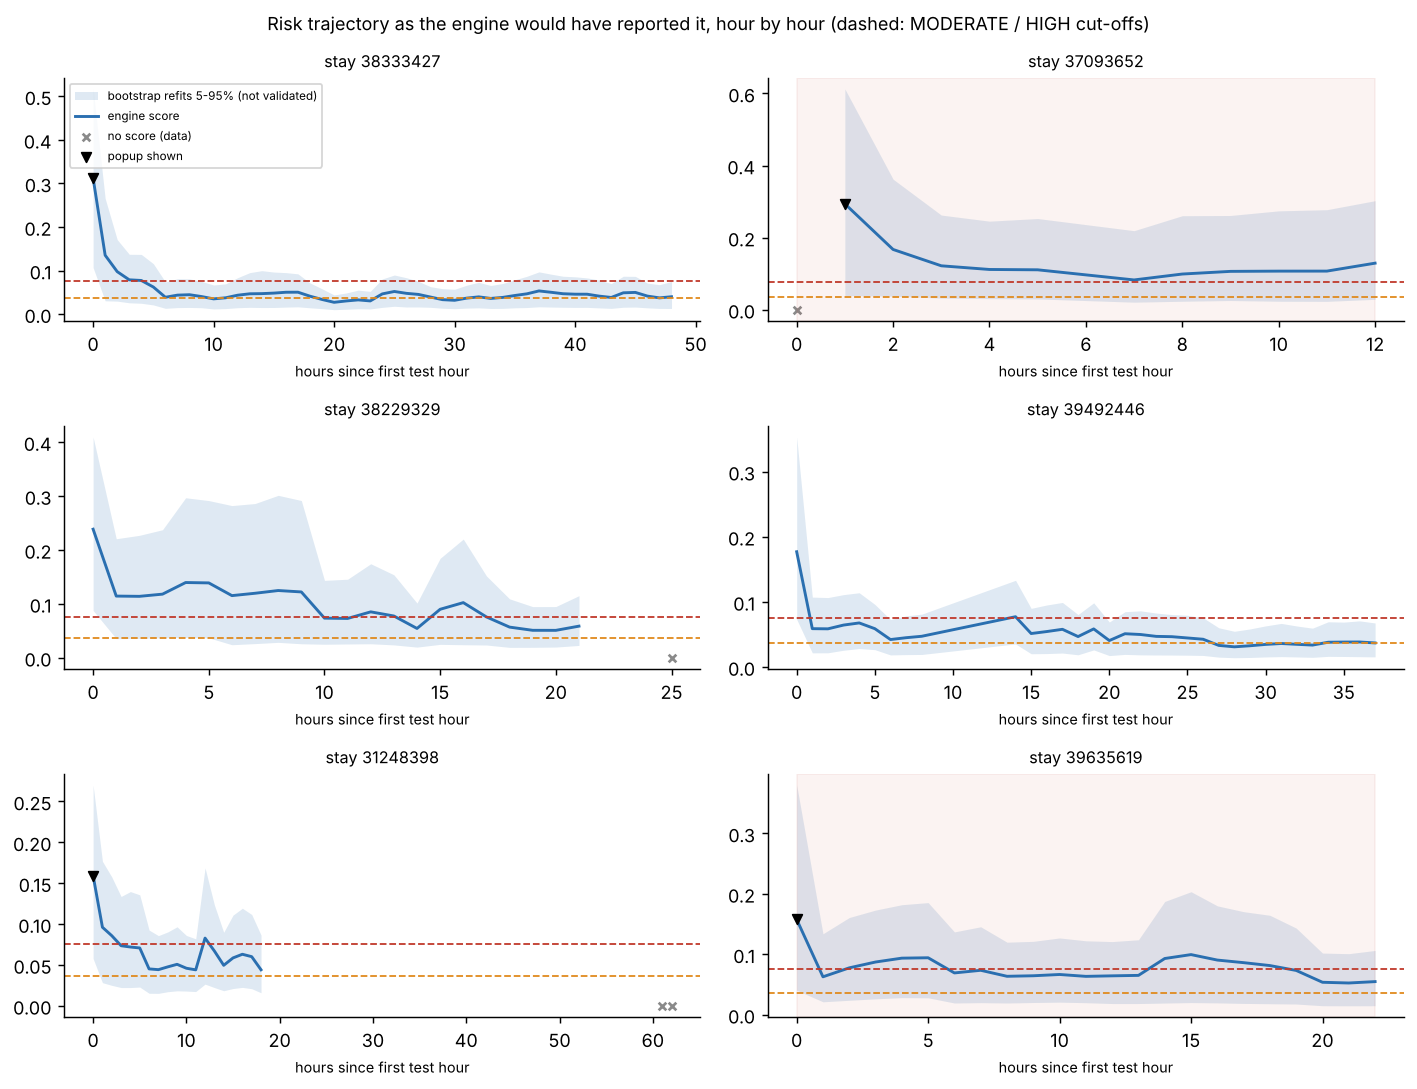

In [14]:
# Risk trajectory over each stay (the score the phone would have shown each hour) with alerts marked
show = STREAM.groupby("stay_id").score.max().sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(3, 2, figsize=(11, 8.5), sharey=False)
th = ENGINE.policy.thresholds
for ax, sid in zip(axes.ravel(), show):
    g = STREAM[STREAM.stay_id == sid].sort_values("hour")
    hrs = (g.hour - g.hour.min()).dt.total_seconds() / 3600
    ax.fill_between(hrs, g.p05, g.p95, color=BLUE, alpha=0.15, lw=0, label="bootstrap refits 5-95% (not validated)")
    ax.plot(hrs, g.score, color=BLUE, lw=1.6, label="engine score")
    ax.axhline(th["moderate"], color=ORANGE, ls="--", lw=1); ax.axhline(th["high"], color=RED, ls="--", lw=1)
    no = g[g.status != "OK"]
    ax.scatter((no.hour - g.hour.min()).dt.total_seconds() / 3600, [0] * len(no), marker="x", color=GREY, s=18, label="no score (data)")
    pop = g[g.popup]
    ax.scatter((pop.hour - g.hour.min()).dt.total_seconds() / 3600, pop.score.fillna(0), marker="v", color="k", s=28, zorder=3, label="popup shown")
    ev = g[g.hours_to_event.notna() & (g.hours_to_event <= 0.5)]
    if g.y_24h.max() == 1:
        first = g[g.y_24h == 1].hour.min()
        ax.axvspan((first - g.hour.min()).total_seconds() / 3600, hrs.max(), color=RED, alpha=0.06, label="event within 24 h")
    ax.set_title(f"stay {sid}", fontsize=9); ax.set_xlabel("hours since first test hour", fontsize=8)
axes[0, 0].legend(fontsize=6.5, loc="upper left")
fig.suptitle("Risk trajectory as the engine would have reported it, hour by hour (dashed: MODERATE / HIGH cut-offs)", fontsize=10)
savefig("02_risk_trajectories")

## 8 · Personal baseline and the early-warning trend detector

In [15]:
r_ex, req_ex = LAST[EX_SID]
print("baseline status:", r_ex.baseline.status.value, "| confidence:", r_ex.baseline.confidence)
for d_ in r_ex.baseline.deviations: print(" -", d_["text"])
print(pd.DataFrame(r_ex.baseline.trends).T[["pattern", "valid_hours", "hours_beyond_threshold", "reference", "reference_value", "threshold", "slope_per_hour"]])
print("corroboration:", r_ex.baseline.corroboration)

bl_rows = []
for sid, (r, _) in LAST.items():
    t = r.baseline.trends
    bl_rows.append({"stay_id": sid, "baseline": r.baseline.status.value, "confidence": r.baseline.confidence,
                    **{f"{s}_pattern": t.get(s, {}).get("pattern") for s in ("hr", "spo2", "rr")},
                    "signals_sustained": r.baseline.corroboration["count"] if r.baseline.corroboration else 0,
                    "corroborated": r.baseline.corroboration["corroborated"] if r.baseline.corroboration else False,
                    **{f"{d_['signal']}_vs_baseline": d_["deviation"] for d_ in r.baseline.deviations}})
BL = pd.DataFrame(bl_rows); BL.to_csv(RES / "baseline_and_trends_last_hour.csv", index=False)
print(BL.baseline.value_counts().to_dict())
cnt = STREAM.groupby("corroborated").agg(hours=("y_24h", "size"), event_within_24h=("y_24h", "mean")).round(3)
print("\nall test hours, corroborated multi-signal change vs not:"); print(cnt)
cnt.to_csv(RES / "corroboration_vs_outcome.csv")

baseline status: AVAILABLE | confidence: HIGH
 - Heart rate is 18 bpm above this patient's baseline (median 80 bpm of 160 hourly readings, 2135-01-06 10:00:00 to 2135-01-13 03:00:00). Latest reading hour: 2135-01-13 09:00:00.
 - Oxygen saturation is 5 % below this patient's baseline (median 95 % of 160 hourly readings, 2135-01-06 10:00:00 to 2135-01-13 03:00:00). Latest reading hour: 2135-01-13 09:00:00.
 - Breathing rate is 5 breaths/min above this patient's baseline (median 16 breaths/min of 161 hourly readings, 2135-01-06 10:00:00 to 2135-01-13 03:00:00). Latest reading hour: 2135-01-13 09:00:00.
        pattern valid_hours hours_beyond_threshold          reference  \
hr    SUSTAINED           5                      5  personal baseline   
spo2  SUSTAINED           5                      4  personal baseline   
rr    SUSTAINED           5                      5  personal baseline   

     reference_value threshold slope_per_hour  
hr              80.0        10           -1.6  
spo2

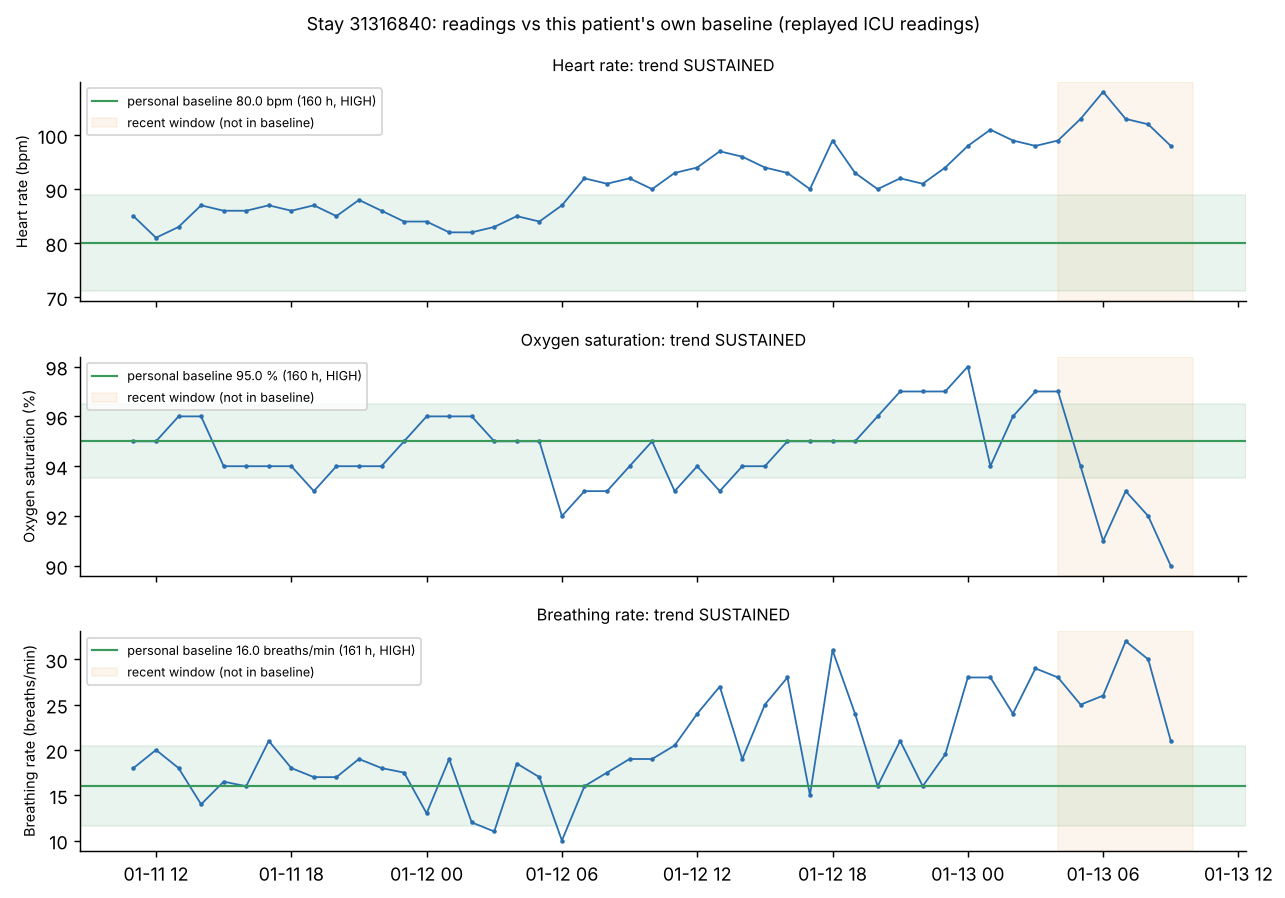

In [16]:
# Baseline panel for the example stay: last 48 h of readings against the personal baseline band
from risk_engine.baseline_engine import UNITS as BU, NAMES as BN
v = input_validator.validate(req_ex["patient_profile"], [], req_ex["wearable_readings"], pd.Timestamp(req_ex["now"]), cfg)
nowx = pd.Timestamp(req_ex["now"])
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, s in zip(axes, ("hr", "spo2", "rr")):
    d_ = v.readings[(v.readings.signal == s) & (v.readings.timestamp > nowx - pd.Timedelta(hours=48))]
    ax.plot(d_.timestamp, d_.value, ".-", color=BLUE, lw=1, ms=3)
    info = r_ex.baseline.by_signal[s]
    if info.get("median") is not None:
        m, sd = info["median"], 1.4826 * info["mad"]
        ax.axhline(m, color=GREEN, lw=1.2, label=f"personal baseline {m} {BU[s]} ({info['n_hours']} h, {info['confidence']})")
        ax.axhspan(m - sd, m + sd, color=GREEN, alpha=0.1)
    ax.axvspan(nowx - pd.Timedelta(hours=6), nowx, color=ORANGE, alpha=0.08, label="recent window (not in baseline)")
    ax.set_ylabel(f"{BN[s]} ({BU[s]})", fontsize=8); ax.legend(fontsize=7, loc="upper left")
    ax.set_title(f"{BN[s]}: trend {r_ex.baseline.trends[s]['pattern']}", fontsize=9)
fig.suptitle(f"Stay {EX_SID}: readings vs this patient's own baseline (replayed ICU readings)", fontsize=10)
savefig("03_personal_baseline_example")

## 9 · Explanations: per patient, and across all replayed hours

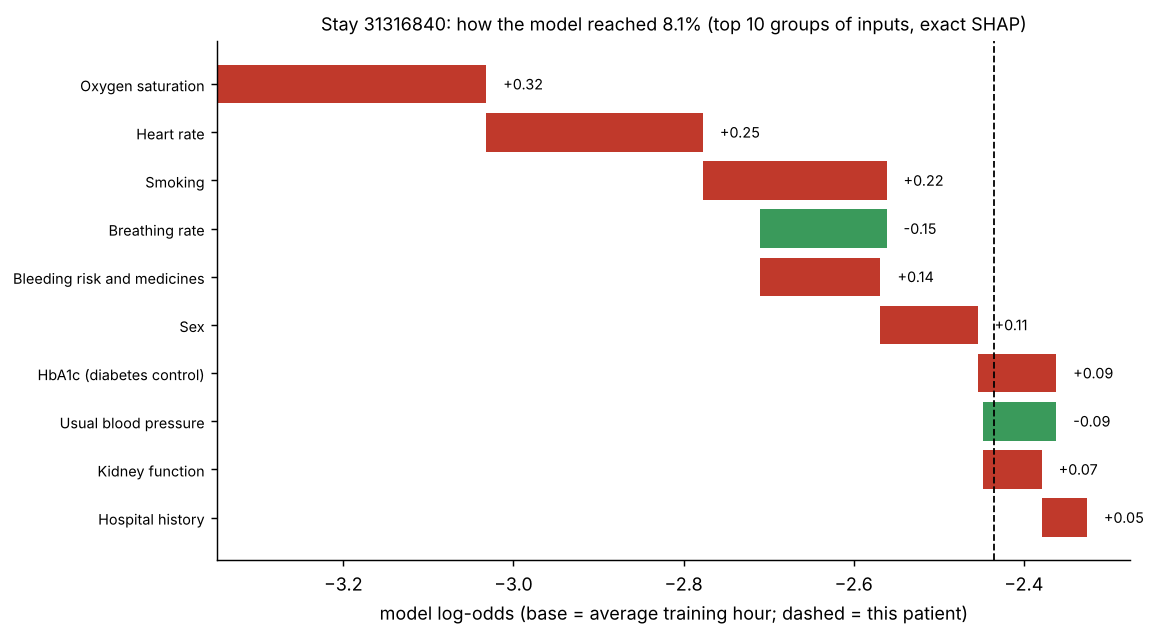

top reason across 1065 scored hours:
top1
Heart rate                  511
Oxygen saturation           194
Breathing rate              127
Smoking                     121
Cholesterol                  53
HbA1c (diabetes control)     22
Sex                          16
Body size                    12


In [17]:
from risk_engine.shap_service import explain
wf = r_ex.explanation.waterfall
steps = wf["steps"][:10]
fig, ax = plt.subplots(figsize=(9, 5))
for i, s in enumerate(steps):
    c = RED if s["shap_log_odds"] > 0 else GREEN
    ax.barh(i, s["end"] - s["start"], left=s["start"], color=c)
    ax.text(max(s["start"], s["end"]) + 0.02, i, f"{s['shap_log_odds']:+.2f}", va="center", fontsize=8)
ax.set_yticks(range(len(steps))); ax.set_yticklabels([s["label"] for s in steps], fontsize=8); ax.invert_yaxis()
ax.axvline(wf["base"], color=GREY, ls=":", lw=1); ax.axvline(wf["final"], color="k", ls="--", lw=1)
ax.set_xlabel("model log-odds (base = average training hour; dashed = this patient)")
ax.set_title(f"Stay {EX_SID}: how the model reached {100 * r_ex.risk.raw_output:.1f}% (top 10 groups of inputs, exact SHAP)", fontsize=10)
savefig("04_waterfall_example")

# global view from the engine's own explanations of every scored hour
OK = STREAM[STREAM.status == "OK"]
print(f"top reason across {len(OK)} scored hours:"); print(OK.top1.value_counts().head(8).to_string())
OK.top1.value_counts().rename("hours_as_top_reason").to_csv(RES / "top_reason_counts_replay.csv")

## 10 · Data quality and confidence monitor

In [18]:
dq_rows = []
for sid, (r, _) in LAST.items():
    fr = r.data_quality.freshness_by_signal
    dq_rows.append({"stay_id": sid, "status": r.status.value, "reason": r.status_reason_code, "coverage_pct": r.data_quality.coverage_pct,
                    "quality_weighted_coverage_pct": r.data_quality.quality_weighted_coverage_pct,
                    **{f"{s}_status": fr[s].status.value for s in ("hr", "spo2", "rr", "rhythm")},
                    **{f"{s}_age_min": fr[s].age_minutes for s in ("hr", "spo2", "rr")},
                    "minutes_since_sync": r.data_quality.minutes_since_last_sync, "n_imputed": len(r.data_quality.imputed_fields),
                    "imputed": ", ".join(i["feature"] for i in r.data_quality.imputed_fields),
                    "n_out_of_distribution": len(r.data_quality.out_of_distribution),
                    "out_of_distribution": ", ".join(o["feature"] for o in r.data_quality.out_of_distribution),
                    "remeasure_flags": len(r.data_quality.flags_for_remeasurement),
                    "uncertainty_p05": (r.risk.uncertainty or {}).get("p05"), "uncertainty_p95": (r.risk.uncertainty or {}).get("p95"),
                    "tier_could_change": (r.risk.uncertainty or {}).get("tier_could_change"), "warnings": " | ".join(r.data_quality.warnings)})
DQM = pd.DataFrame(dq_rows); DQM.to_csv(RES / "data_quality_monitor_last_hour.csv", index=False)
print(DQM[["stay_id", "status", "reason", "coverage_pct", "hr_status", "spo2_status", "rr_status", "n_imputed", "n_out_of_distribution",
           "uncertainty_p05", "uncertainty_p95", "tier_could_change"]].to_string(index=False))

 stay_id            status     reason  coverage_pct hr_status spo2_status rr_status  n_imputed  n_out_of_distribution  uncertainty_p05  uncertainty_p95 tier_could_change
30876334                OK       None         100.0     FRESH       FRESH     FRESH          7                      0           0.0106           0.0380              True
31248398 INSUFFICIENT_DATA STALE_DATA           5.5     FRESH       STALE     FRESH          0                      0              NaN              NaN              None
31316840                OK       None          95.8     FRESH       FRESH     FRESH          5                      0           0.0222           0.2002              True
32145159                OK       None          95.8     FRESH       FRESH     FRESH          4                      0           0.0159           0.0951              True
32166508                OK       None          95.8     FRESH       FRESH     FRESH          7                      0           0.0097           0.032

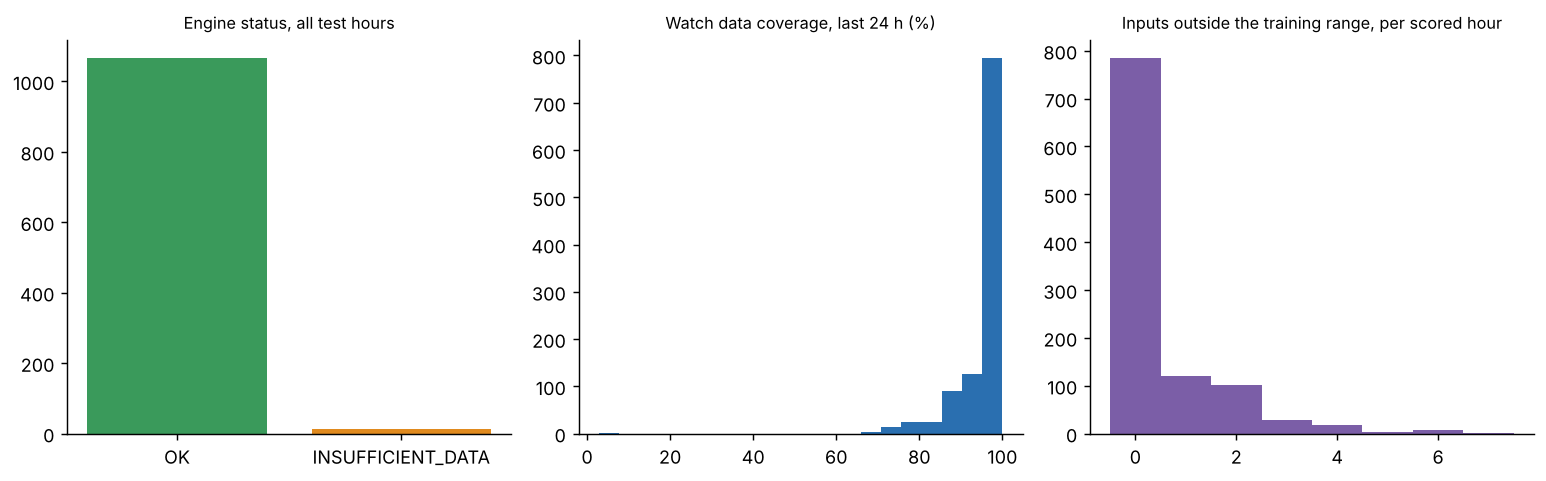

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
s = STREAM.status.value_counts()
axes[0].bar(s.index, s.values, color=[GREEN if i == "OK" else ORANGE if i == "INSUFFICIENT_DATA" else RED for i in s.index])
axes[0].set_title("Engine status, all test hours", fontsize=9)
axes[1].hist(STREAM.coverage_pct.dropna(), bins=20, color=BLUE); axes[1].set_title("Watch data coverage, last 24 h (%)", fontsize=9)
ok = STREAM[STREAM.status == "OK"]
axes[2].hist(ok.n_ood, bins=range(0, int(ok.n_ood.max()) + 2), color=PURPLE, align="left")
axes[2].set_title("Inputs outside the training range, per scored hour", fontsize=9)
savefig("05_data_quality_monitor")

## 11 · What-if digital-twin simulator

Clinician-only, on copies of the request. Nothing is written to the patient's record, no alert is raised and nothing is audited
as a real result. Results are **hypothetical model simulations**, not predicted treatment effects and not advice.

In [20]:
WI = []
for sid in STAYS:
    rq = R.request(sid, R.last_hour(sid))
    before = copy.deepcopy(rq)
    for name, ch in [("heart rate 10 bpm lower (last 6 h)", "hr-10"), ("SpO2 2 points higher (last 6 h)", "spo2+2"), ("non-smoker", "smoker0")]:
        r0 = LAST[sid][0]
        if r0.status.value != "OK":
            continue
        latest = {x["signal"]: x["value"] for x in rq["wearable_readings"] if x["signal"] in ("hr", "spo2")}
        changes = {"hr-10": {"hr": max(30, latest.get("hr", 80) - 10)}, "spo2+2": {"spo2": min(100, latest.get("spo2", 95) + 2)},
                   "smoker0": {"smoker": 0}}[ch]
        o = whatif.simulate(STREAM_ENGINE, rq, changes, role="clinician")
        WI.append({"stay_id": sid, "scenario": name, "status": o["status"], "original": o["original"]["score"], "original_tier": o["original"]["tier"],
                   "simulated": o["simulated"]["score"], "simulated_tier": o["simulated"]["tier"], "difference": o.get("difference"),
                   "top_changed_input": (o.get("changed_model_inputs") or [{}])[0].get("feature")})
    assert rq == before, "what-if changed the request"
WIF = pd.DataFrame(WI); WIF.to_csv(RES / "what_if_simulations.csv", index=False)
print(whatif.LABEL); print()
print(WIF.groupby("scenario").agg(stays=("stay_id", "size"), mean_change=("difference", "mean"),
      tier_changed=("original_tier", lambda x: int((x != WIF.loc[x.index, "simulated_tier"]).sum()))).round(4))
try:
    whatif.simulate(STREAM_ENGINE, rq, {"hr": 70}, role="patient")
except Exception as e:
    print("\npatient role:", type(e).__name__, e)

HYPOTHETICAL MODEL SIMULATION. It shows how this model's output responds to edited inputs. It does not change the patient's record, does not predict the effect of any treatment and is not medical advice.

                                    stays  mean_change  tier_changed
scenario                                                            
SpO2 2 points higher (last 6 h)        17      -0.0023             3
heart rate 10 bpm lower (last 6 h)     17      -0.0089             7
non-smoker                             17      -0.0033             4

patient role: PermissionDenied Role 'patient' may not run what-if simulations.


## 12 · Model observability: input drift and outcome-based performance

In [21]:
Xs = []
for sid in STAYS:
    rq = R.request(sid, R.last_hour(sid)); now = pd.Timestamp(rq["now"])
    v = input_validator.validate(rq["patient_profile"], rq["clinical_readings"], rq["wearable_readings"], now, cfg)
    tab = feature_builder.hourly_table(v.readings, now, v.profile.get("hist_af"))
    X = feature_builder.feature_matrix(tab, feature_builder.static_values(v), ENGINE.model.features).assign(hour=tab.hour.values)
    Xs.append(X[X.hour.isin(R.test[R.test.stay_id == sid].hour)].drop(columns="hour"))
XT = pd.concat(Xs)
DRIFT = drift_service.input_drift(ENGINE.model.reference, XT, cfg)
DRIFT.to_csv(RES / "input_drift_test_vs_train.csv", index=False)
print(DRIFT.status.value_counts().to_dict()); print(DRIFT.head(10).to_string(index=False))

lab = STREAM[STREAM.status == "OK"]
PERF = drift_service.outcome_performance(lab.score, lab.y_24h, ENGINE.policy.thresholds)
PERF["note"] = "test hours that the engine scored, with their verified 24 h outcome; 4 event stays only, so wide uncertainty"
dump(PERF, RES / "outcome_performance_engine_stream.json"); print(json.dumps(PERF, indent=1))

{'ALERT': 20, 'OK': 14, 'WARNING': 6}
      feature    psi status  missing_pct_now  missing_pct_train  median_now  median_train
triglycerides 7.0416  ALERT             64.9              68.71       137.0         79.00
        hba1c 5.7640  ALERT             42.8              76.70         7.5          8.50
 tc_hdl_ratio 5.7543  ALERT             83.7              74.61         3.0          2.84
          ldl 4.1520  ALERT             83.7              74.61       142.0        121.00
      non_hdl 4.0920  ALERT             83.7              74.61       107.0        135.00
   total_chol 3.7931  ALERT             83.7              74.61       172.0        219.00
         egfr 2.9780  ALERT              0.0               0.00        73.6         95.90
   weight_lbs 2.8477  ALERT              0.0               0.00       171.4        164.00
 age_at_admit 2.6407  ALERT              0.0               0.00        65.0         59.00
    height_in 2.3782  ALERT              0.0               0.0

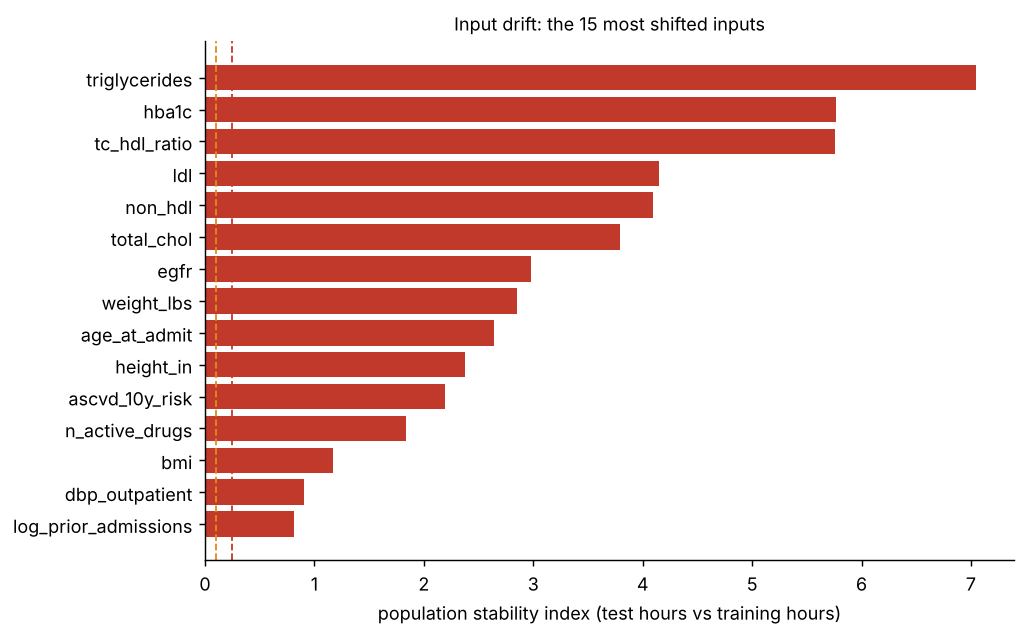

In [22]:
t = DRIFT.dropna(subset=["psi"]).head(15).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(t.feature, t.psi, color=[RED if s == "ALERT" else ORANGE if s == "WARNING" else GREEN for s in t.status])
plt.axvline(cfg["drift"]["psi_warning"], color=ORANGE, ls="--", lw=1); plt.axvline(cfg["drift"]["psi_alert"], color=RED, ls="--", lw=1)
plt.xlabel("population stability index (test hours vs training hours)")
plt.title("Input drift: the 15 most shifted inputs", fontsize=10)
savefig("06_input_drift")

## 13 · Audit trail and reproducibility (audit replay)

In [23]:
AU = pd.DataFrame(STREAM_ENGINE.audit.records.values())
AU.drop(columns=["thresholds", "top_reasons", "data_quality", "alert_decision", "retention"]).to_csv(RES / "audit" / "audit_log_replay.csv", index=False)
example = STREAM_ENGINE.audit.records[LAST[EX_SID][0].audit.audit_id]
dump(example, RES / "audit" / f"audit_record_example_{EX_SID}.json")
print(json.dumps(example, indent=1)[:1800])
blob = json.dumps(list(STREAM_ENGINE.audit.records.values()))
print("\nraw subject ids found in audit records:", sum(f"mimic-subject-{s}" in blob for s in R.test.subject_id.unique()))

# replay 25 audited evaluations from their stored snapshots and compare result hashes
rng = np.random.default_rng(7)
ids = rng.choice(list(STREAM_ENGINE.audit.snapshots), 25, replace=False)
same = 0
for aid in ids:
    snap = STREAM_ENGINE.audit.snapshots[aid]["snapshot"]
    rr = ENGINE.evaluate({**snap["profile"], "patient_id": "replay"}, snap["clinical"], snap["wearable"], baseline=snap["baseline"],
                         now=snap["now"], patient_reference=snap["patient_reference"], record=False, simulation=False)
    same += rr.audit.result_sha256 == STREAM_ENGINE.audit.records[aid]["result_sha256"]
print(f"audit replay: {same} of {len(ids)} results reproduced exactly (same SHA-256)")
later = STREAM.hour.max() + pd.Timedelta(days=40)
due = sum(later - pd.Timestamp(s["stored_at"]) > pd.Timedelta(days=cfg["privacy"]["snapshot_retention_days"]) for s in STREAM_ENGINE.audit.snapshots.values())
print(f"retention: 40 days after the last evaluation, {due} of {len(STREAM_ENGINE.audit.snapshots)} input snapshots would be purged "
      f"({cfg['privacy']['snapshot_retention_days']}-day limit); audit records are kept {cfg['privacy']['audit_retention_days']} days")

{
 "audit_id": "34e78b5a-f154-5fc9-9edc-999230f5fe30",
 "evaluated_at": "2135-01-13 10:00:00",
 "recorded_at": "2135-01-13 10:00:00",
 "patient_reference": "pt_1556483fba7c5ed3",
 "input_reference": "in_923cf2faef23c161c0aad235753c532e",
 "is_demo_data": true,
 "simulation": false,
 "status": "OK",
 "status_reason_code": null,
 "model_version": "1.0.0+2026-10-18",
 "model_sha256": "c66823982669d7cc6fd5e1d7f0277566144efc51cb553cfeb75b591c7ad43752",
 "calibration": "uncalibrated",
 "policy_version": "RE-POLICY-1.0-provisional",
 "thresholds": {
  "moderate": 0.0362,
  "high": 0.0759
 },
 "raw_output": 0.080576,
 "calibrated_probability": null,
 "tier": "HIGH",
 "emergency_state": "REVIEW_REQUIRED",
 "emergency_rule": "EMG-VIT-00",
 "emergency_rules_version": "EMG-RULES-1.0-draft",
 "explanation_status": "AVAILABLE",
 "explanation_version": "SHAP-linear-exact-1.0",
 "top_reasons": [
  {
   "reason": "Oxygen saturation",
   "shap_log_odds": 0.3162
  },
  {
   "reason": "Heart rate",
   "sh

audit replay: 25 of 25 results reproduced exactly (same SHA-256)
retention: 40 days after the last evaluation, 1077 of 1077 input snapshots would be purged (30-day limit); audit records are kept 365 days


## 14 · Alert lifecycle and clinician review

The lifecycle on the emergency alert from section 6: displayed, acknowledged by the patient (which does **not** mean they are
better), call option used, reviewed and escalated by a clinician. Resolving needs a clinician, a note and a valid new result in
which the rule is no longer met; stale data is refused.

In [24]:
al = EM_ENGINE.alerts; aid = em_res.alert["alert_id"]
al.mark_displayed(aid, now0)
al.acknowledge(aid, now0 + pd.Timedelta(minutes=1), "patient-phone", "patient")
al.record_user_action(aid, now0 + pd.Timedelta(minutes=1), "patient-phone", "patient", "opened_dialer_112")
for role, fn in [("patient", lambda: al.resolve(aid, now0, "patient-phone", "patient", "I feel fine", em_res))]:
    try: fn()
    except Exception as e: print(f"{role} tries to resolve -> {type(e).__name__}: {e}")
al.clinician_review(aid, now0 + pd.Timedelta(minutes=6), "dr-demo", "clinician", "IN_REVIEW", "Phoned the patient; review in progress")
al.escalate(aid, now0 + pd.Timedelta(minutes=7), "dr-demo", "clinician", to="on-call cardiology")
stale = EM_ENGINE.evaluate(**{**base_req, "now": now0 + pd.Timedelta(hours=6)}, record=False)
try:
    al.resolve(aid, now0 + pd.Timedelta(hours=6), "dr-demo", "clinician", "No new readings", stale)
except ValueError as e:
    print("resolve on stale data ->", e)
life = al.public(al.alerts[aid])
dump(life, RES / "alert_lifecycle_example.json")
print(pd.DataFrame(life["history"])[["event", "at", "actor"]].to_string(index=False))
print("state:", life["state"], "| notifications:", life["notifications"])

patient tries to resolve -> PermissionDenied: Role 'patient' may not 'resolve'.
resolve on stale data -> Cannot resolve: the latest evaluation is not a valid result (missing or stale data does not resolve an alert).
       event                  at         actor
         NEW 2135-01-13 10:00:00          None
   DISPLAYED 2135-01-13 10:00:00     phone-app
ACKNOWLEDGED 2135-01-13 10:01:00 patient-phone
 USER_ACTION 2135-01-13 10:01:00 patient-phone
    REVIEWED 2135-01-13 10:06:00       dr-demo
   ESCALATED 2135-01-13 10:07:00       dr-demo
state: ESCALATED | notifications: [{'at': '2135-01-13 10:00:00', 'channel': 'push', 'success': False, 'error': 'no notification channel configured (demo)'}]


## 15 · Phone and watch payloads, and downloadable reports

In [25]:
pay_rows = []
for sid, (r, _) in LAST.items():
    vw = views.all_views(r)
    dump(vw, PAY / f"stay_{sid}.json")
    report.save(r, REP, f"stay_{sid}")
    pay_rows.append({"stay_id": sid, "patient_screen": vw["phone_patient"]["screen"], "watch_title": vw["watch"].get("title"),
                     "doctor_tier": vw["phone_doctor"]["header"]["tier"], "emergency": r.emergency.state.value})
report.save(em_res, REP, "demo_emergency_symptoms")
dump(views.all_views(em_res), PAY / "demo_emergency_symptoms.json")
stale_r = ENGINE.evaluate(**{**base_req, "now": now0 + pd.Timedelta(hours=5)}, record=False, simulation=True)
dump(views.all_views(stale_r), PAY / "demo_insufficient_data.json"); report.save(stale_r, REP, "demo_insufficient_data")
PAYT = pd.DataFrame(pay_rows); PAYT.to_csv(RES / "screens_last_hour.csv", index=False)
print(PAYT.to_string(index=False))
print("\nINSUFFICIENT_DATA patient screen:", json.dumps(views.phone_patient(stale_r), indent=1)[:700])
display(Markdown((REP / f"stay_{EX_SID}.md").read_text()[:3000]))

 stay_id patient_screen watch_title doctor_tier       emergency
30876334            LOW    No alert         LOW   NOT_TRIGGERED
31248398  CANNOT_UPDATE  Re-measure        None REVIEW_REQUIRED
31316840           HIGH  Re-measure        HIGH REVIEW_REQUIRED
32145159       MODERATE Check phone    MODERATE   NOT_TRIGGERED
32166508            LOW    No alert         LOW   NOT_TRIGGERED
32374504            LOW    No alert         LOW   NOT_TRIGGERED
32506122       MODERATE Check phone    MODERATE   NOT_TRIGGERED
33083787       MODERATE Check phone    MODERATE   NOT_TRIGGERED
35026312            LOW    No alert         LOW   NOT_TRIGGERED
36496303            LOW    No alert         LOW   NOT_TRIGGERED
36893762       MODERATE Check phone    MODERATE   NOT_TRIGGERED
37093652           HIGH   High risk        HIGH   NOT_TRIGGERED
37267577            LOW    No alert         LOW   NOT_TRIGGERED
38229329  CANNOT_UPDATE   No update        None  NOT_ASSESSABLE
38333427       MODERATE  Re-measure    M

# CardioTwin risk report

**Generated:** 2135-01-13T10:00:00 UTC · **Patient reference:** pt_1556483fba7c5ed3 · **Audit id:** 34e78b5a-f154-5fc9-9edc-999230f5fe30

> DEMO DATA: replayed MIMIC-IV ICU readings, not real watch data.

**Summary:** HIGH: 8.1% for first vasopressor start, lactate >= 4 mmol/L or in-hospital death within 24 hours; data warnings: 2.

| | |
|---|---|
| Status | OK |
| Score | 8.1% (model probability (0-1), uncalibrated) |
| Tier | HIGH (provisional policy RE-POLICY-1.0-provisional) |
| Target / horizon | first vasopressor start, lactate >= 4 mmol/L or in-hospital death / 24 hours |
| Model | cardiotwin-watch-24h 1.0.0+2026-10-18 (uncalibrated) |
| Emergency state | REVIEW_REQUIRED |
| Data quality | SUFFICIENT, coverage 95.8% |

## Situation

- Model output 8.1% (model probability (uncalibrated)) for first vasopressor start, lactate >= 4 mmol/L or in-hospital death within 24 hours; tier HIGH (provisional cut-offs: MODERATE >= 0.0362, HIGH >= 0.0759).  
  <sub>Evidence: type=model, model_version=1.0.0+2026-10-18; type=policy, policy_version=RE-POLICY-1.0-provisional; type=model_output</sub>
- Evaluated at 2135-01-13 10:00:00.  
  <sub>Evidence: type=calculation</sub>
- Latest valid watch readings: Heart rate at 2135-01-13 09:00:00 (60 min old, fresh); SpO2 at 2135-01-13 09:00:00 (60 min old, fresh); Breathing rate at 2135-01-13 09:00:00 (60 min old, fresh).  
  <sub>Evidence: type=reading, signal=hr, timestamp=2135-01-13 09:00:00; type=reading, signal=spo2, timestamp=2135-01-13 09:00:00; type=reading, signal=rr, timestamp=2135-01-13 09:00:00</sub>
- 5 model inputs were not available and were filled with training medians: non_hdl, total_chol, tc_hdl_ratio, triglycerides, ldl.  
  <sub>Evidence: type=imputation</sub>

## Assessment

- Oxygen saturation: current oxygen saturation is 90% (typical 97%); oxygen saturation in the previous hour is 92% (typical 97%). This raises the model output (odds x1.37).  
  <sub>Evidence: type=model, model_version=1.0.0+2026-10-18; type=feature, feature=spo2, time_window=latest hour; type=feature, feature=spo2_lag1, time_window=previous hour</sub>
- Heart rate: average heart rate over the last 6 h is 102 bpm (typical 87 bpm); heart rate in the previous hour is 102 bpm (typical 86 bpm). This raises the model output (odds x1.29).  
  <sub>Evidence: type=model, model_version=1.0.0+2026-10-18; type=feature, feature=hr_mean6h, time_window=last 6 h; type=feature, feature=hr_lag1, time_window=previous hour</sub>
- Smoking: the patient is a smoker. This raises the model output (odds x1.24).  
  <sub>Evidence: type=model, model_version=1.0.0+2026-10-18; type=feature, feature=smoker, time_window=profile / EHR value</sub>
- Heart rate is 18 bpm above this patient's baseline (median 80 bpm of 160 hourly readings, 2135-01-06 10:00:00 to 2135-01-13 03:00:00). Latest reading hour: 2135-01-13 09:00:00.  
  <sub>Evidence: type=baseline, signal=hr; type=reading, signal=hr, timestamp=2135-01-13 09:00:00</sub>
- 

## 16 · Automated tests (scenarios A-S)

In [26]:
t0 = time.time()
p = subprocess.run([sys.executable, "-m", "pytest", "risk_engine/tests", "-q", "-p", "no:cacheprovider", "-W", "ignore",
                    f"--junitxml={RES / 'test_results.xml'}"], cwd=ROOT, capture_output=True, text=True)
print(p.stdout[-2500:]); print(p.stderr[-1500:])
print(f"exit code {p.returncode}, {time.time() - t0:.0f} s")
import xml.etree.ElementTree as ET
ts = ET.parse(RES / "test_results.xml").getroot()
ts = ts if ts.tag == "testsuite" else ts[0]
TESTS = pd.DataFrame([{"test": c.get("name"), "file": c.get("classname"), "time_s": float(c.get("time")),
                       "result": "failed" if c.find("failure") is not None or c.find("error") is not None else "skipped" if c.find("skipped") is not None else "passed"}
                      for c in ts.iter("testcase")])
TESTS.to_csv(RES / "test_results.csv", index=False)
print(TESTS.result.value_counts().to_dict())

................................................                         [100%]
48 passed in 13.36s


exit code 0, 15 s
{'passed': 48}


## 17 · Summary

In [27]:
SUMMARY = {
    "engine_version": risk_engine.ENGINE_VERSION, "policy_version": cfg["policy_version"], "model": ENGINE.model.info()["version"],
    "calibration": ENGINE.model.calibration_status, "thresholds": ENGINE.policy.thresholds,
    "parity_vs_nb05": {"hours": int(len(PAR)), "same_tier_pct": round(100 * PAR.same_tier.mean(), 1),
                       "median_abs_diff": float(PAR.abs_diff.median()), "max_abs_diff": float(PAR.abs_diff.max()),
                       "exact_features_pct_stays_without_gaps": round(100 * (PAR[~PAR.stay_has_hour_gaps].n_feature_mismatch == 0).mean(), 1)},
    "replay": {"evaluations": int(len(STREAM)), **{k: int(v) for k, v in STREAM.status.value_counts().items()},
               "popups": int(STREAM.popup.sum()), "popups_without_dedup_cooldown": naive,
               "emergency_triggered_hours": int((STREAM.emergency == "TRIGGERED").sum()),
               "emergency_review_hours": int((STREAM.emergency == "REVIEW_REQUIRED").sum())},
    "outcome_performance": PERF, "drift_inputs_alert": int((DRIFT.status == "ALERT").sum()),
    "audit_replay_reproduced": f"{same}/{len(ids)}",
    "tests": TESTS.result.value_counts().to_dict(),
}
dump(SUMMARY, RES / "risk_engine_summary.json")
print(json.dumps(SUMMARY, indent=1))

{
 "engine_version": "risk-engine-1.0.0",
 "policy_version": "RE-POLICY-1.0-provisional",
 "model": "1.0.0+2026-10-18",
 "calibration": "uncalibrated",
 "thresholds": {
  "moderate": 0.0362,
  "high": 0.0759
 },
 "parity_vs_nb05": {
  "hours": 1077,
  "same_tier_pct": 99.7,
  "median_abs_diff": 3.990711293755389e-06,
  "max_abs_diff": 0.04162187286084461,
  "exact_features_pct_stays_without_gaps": 81.5
 },
 "replay": {
  "evaluations": 1077,
  "OK": 1065,
  "INSUFFICIENT_DATA": 12,
  "popups": 15,
  "popups_without_dedup_cooldown": 750,
  "emergency_triggered_hours": 0,
  "emergency_review_hours": 202
 },
 "outcome_performance": {
  "n_predictions_with_outcome": 1065,
  "events": 80,
  "mean_predicted": 0.0505,
  "observed_rate": 0.0751,
  "AUROC": 0.731,
  "AUPRC": 0.1936,
  "Brier": 0.0677,
  "sensitivity_high": 0.325,
  "ppv_high": 0.25,
  "calibration_in_the_large": 0.0246,
  "note": "test hours that the engine scored, with their verified 24 h outcome; 4 event stays only, so wide u

### Not built, and why

* **Sleep, activity/steps, true HRV, watch blood pressure, skin temperature** (`sleep_change_hours`, `activity_change_24h_pct`,
  `hrv_deviation_from_baseline`, `bp_change_from_baseline`): the data has no such readings, so the engine reports them as
  unavailable instead of inventing them. The hourly heart-rate spread (`hr_sd_24h`) is not HRV.
* **A validated confidence interval**: the bootstrap range shows model variance only.
* **Real emergency dispatch**: the call option opens the phone dialler; automatic dispatch would need consent, an authorised
  emergency-service integration and clinical, legal and operational review.
* **Push notifications**: no notification channel is connected, so every alert records "not sent (no channel configured)".
* **A web dashboard**: by design, the screens are the phone app and the watch; the engine returns their payloads.

### Needs clinical review before any real-world use

Risk cut-offs, the hysteresis margin and cooldown; every emergency rule, its confirmation window and reading-age limit; the
emergency guidance text and the 112 call option for the deployment region; the recommendation policy in the SAR; the freshness
limits per signal; the plausibility (re-measure) limits; the baseline and trend thresholds.